### Breast cancer

In [3]:
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd
import os

##### Fsocre

In [ ]:
# 加载数据集
file_path = '../Fscore/breast_sample_FscoreSorted_selected74.csv'
Fscoredata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [48]:
Fscoredata

,class,MOTIF_END_CAAC,MOTIF_END_CAGT,MOTIF_END_CATC,MOTIF_END_GACT,MOTIF_END_CAAG,MOTIF_END_TGCA,MOTIF_END_CAGA,MOTIF_END_CGAA,MOTIF_END_TAGC,...,GWMD_chr8_144,MOTIF_END_TGAG,GWMD_chr1_122,MOTIF_END_AGTC,GWMD_chr10_134,GWFP_total_18:1-5000000,flen_170,CNA_7:2000001-3000000,GWMD_chr7_154,GWMD_chr8_140
0,1,0.003608,0.005748,0.004128,0.002793,0.006604,0.004784,0.009053,0.000694,0.002802,...,0.805088,0.006220,0.723697,0.003032,0.786358,0.745205,0.022745,1.04782,0.760707,0.784303
1,1,0.003710,0.006004,0.004354,0.002654,0.007001,0.004583,0.009886,0.000653,0.002788,...,0.754976,0.006089,0.751826,0.003064,0.759322,0.613242,0.024009,1.04467,0.711127,0.789017
2,1,0.003603,0.005624,0.004209,0.002708,0.006578,0.004733,0.009014,0.000681,0.002802,...,0.819042,0.006223,0.758863,0.003004,0.816144,0.673463,0.023165,1.01234,0.762988,0.807759
3,1,0.003562,0.005665,0.004130,0.002745,0.006603,0.004872,0.009088,0.000698,0.002799,...,0.803956,0.006319,0.779191,0.002999,0.795066,0.787853,0.022943,1.08099,0.795455,0.825960
4,1,0.003683,0.005842,0.004136,0.002619,0.006833,0.004480,0.009524,0.000672,0.002923,...,0.762632,0.006205,0.714324,0.003104,0.754928,0.867400,0.023450,1.04487,0.660580,0.695200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,0,0.003496,0.005631,0.004066,0.002673,0.006527,0.005118,0.009070,0.000702,0.002767,...,0.779653,0.006496,0.736079,0.002990,0.766656,0.730956,0.022826,1.10431,0.747176,0.792553
442,0,0.003351,0.005359,0.004113,0.002734,0.005770,0.005404,0.007958,0.000767,0.002551,...,0.746752,0.006604,0.752760,0.003119,0.745777,0.937162,0.022583,1.02818,0.694405,0.756402
443,0,0.003230,0.005557,0.003810,0.002965,0.006036,0.005511,0.008416,0.000851,0.002696,...,0.792103,0.007035,0.778504,0.002930,0.806590,0.819071,0.022008,1.06545,0.804194,0.816159
444,0,0.003439,0.005453,0.004142,0.002760,0.006079,0.005020,0.008365,0.000701,0.002622,...,0.753494,0.006321,0.748511,0.003077,0.767496,0.837387,0.023314,1.04939,0.734128,0.786105


In [ ]:
# 准备训练和测试集函数
def prepare_train_test_Fscore(data, cancer_type, output_dir):
    
    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Fscore/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [61]:
Breast_leaderboard_Fscore = prepare_train_test_Fscore(Fscoredata, "Breast cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       187.72 GB / 251.54 GB (74.6%)
Disk Space Avail:   8944.43 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [64]:
Breast_leaderboard_Fscore.to_csv("breast_leaderboard_Fscore.csv", index=False)
Breast_leaderboard_Fscore

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI_BAG_L1,0.923457,0.855556,0.855556,0.711287,0.853933,0.863636,0.844444,0.923457,0.898056,roc_auc,0.747238,0.175372,7.275097,0.747238,0.175372,7.275097,1,True,3
1,WeightedEnsemble_L2,0.922469,0.833333,0.833333,0.666831,0.835165,0.826087,0.844444,0.922469,0.899539,roc_auc,0.952608,0.287402,9.112444,0.002026,0.000485,0.026634,2,True,5
2,RandomForest_BAG_L1,0.881975,0.822222,0.822222,0.645082,0.826087,0.808511,0.844444,0.881975,0.857625,roc_auc,0.050159,0.104043,1.247901,0.050159,0.104043,1.247901,1,True,2
3,LightGBM_BAG_L1,0.878025,0.811111,0.811111,0.623610,0.817204,0.791667,0.844444,0.878025,0.856963,roc_auc,0.153185,0.007503,0.562812,0.153185,0.007503,0.562812,1,True,1
4,XGBoost_BAG_L1,0.870123,0.777778,0.777778,0.560561,0.791667,0.745098,0.844444,0.870123,0.849482,roc_auc,0.266716,0.043599,0.991487,0.266716,0.043599,0.991487,1,True,4


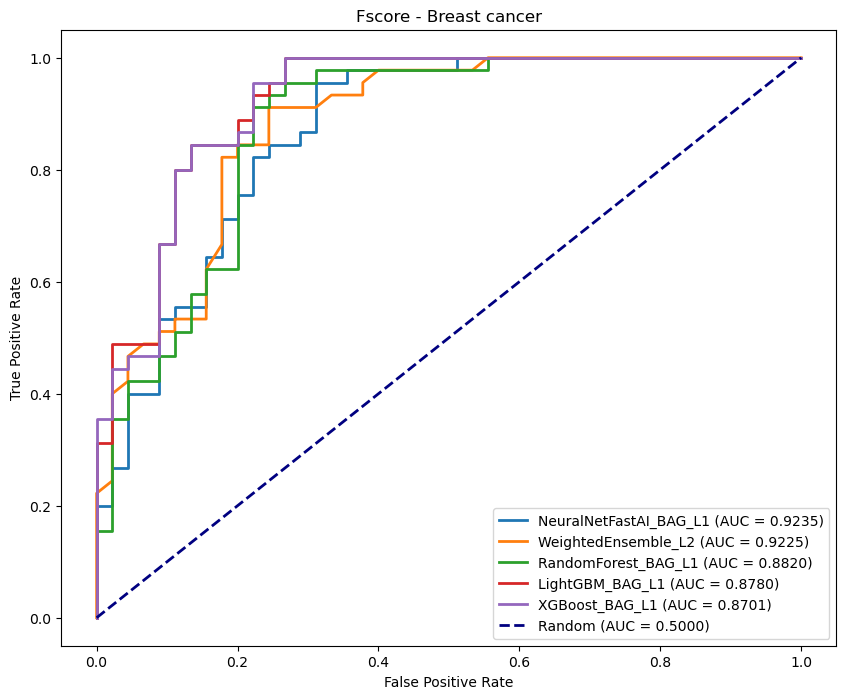

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_Fscore(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)  # 只取正类概率
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Fscore - Breast cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Breast cancer/Fscore'
data = Fscoredata 
plot_roc_curves_Fscore(data, model_dir)


##### ANOVA

In [5]:
# 加载数据集
file_path = '../ANOVA/breast_sample_AnovaSorted_selected74.csv'
ANOVAdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [6]:
ANOVAdata

,class,MOTIF_END_CAAC,MOTIF_END_CAGT,MOTIF_END_CATC,MOTIF_END_GACT,MOTIF_END_CAAG,MOTIF_END_TGCA,MOTIF_END_CAGA,MOTIF_END_CGAA,MOTIF_END_TAGC,...,GWMD_chr8_144,MOTIF_END_TGAG,GWMD_chr1_122,MOTIF_END_AGTC,GWMD_chr10_134,GWFP_total_18:1-5000000,flen_170,CNA_7:2000001-3000000,GWMD_chr7_154,GWMD_chr8_140
0,1,0.003608,0.005748,0.004128,0.002793,0.006604,0.004784,0.009053,0.000694,0.002802,...,0.805088,0.006220,0.723697,0.003032,0.786358,0.745205,0.022745,1.04782,0.760707,0.784303
1,1,0.003710,0.006004,0.004354,0.002654,0.007001,0.004583,0.009886,0.000653,0.002788,...,0.754976,0.006089,0.751826,0.003064,0.759322,0.613242,0.024009,1.04467,0.711127,0.789017
2,1,0.003603,0.005624,0.004209,0.002708,0.006578,0.004733,0.009014,0.000681,0.002802,...,0.819042,0.006223,0.758863,0.003004,0.816144,0.673463,0.023165,1.01234,0.762988,0.807759
3,1,0.003562,0.005665,0.004130,0.002745,0.006603,0.004872,0.009088,0.000698,0.002799,...,0.803956,0.006319,0.779191,0.002999,0.795066,0.787853,0.022943,1.08099,0.795455,0.825960
4,1,0.003683,0.005842,0.004136,0.002619,0.006833,0.004480,0.009524,0.000672,0.002923,...,0.762632,0.006205,0.714324,0.003104,0.754928,0.867400,0.023450,1.04487,0.660580,0.695200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,0,0.003496,0.005631,0.004066,0.002673,0.006527,0.005118,0.009070,0.000702,0.002767,...,0.779653,0.006496,0.736079,0.002990,0.766656,0.730956,0.022826,1.10431,0.747176,0.792553
442,0,0.003351,0.005359,0.004113,0.002734,0.005770,0.005404,0.007958,0.000767,0.002551,...,0.746752,0.006604,0.752760,0.003119,0.745777,0.937162,0.022583,1.02818,0.694405,0.756402
443,0,0.003230,0.005557,0.003810,0.002965,0.006036,0.005511,0.008416,0.000851,0.002696,...,0.792103,0.007035,0.778504,0.002930,0.806590,0.819071,0.022008,1.06545,0.804194,0.816159
444,0,0.003439,0.005453,0.004142,0.002760,0.006079,0.005020,0.008365,0.000701,0.002622,...,0.753494,0.006321,0.748511,0.003077,0.767496,0.837387,0.023314,1.04939,0.734128,0.786105


In [30]:
# 准备训练和测试集函数
def prepare_train_test_ANOVA(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ANOVA/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [31]:
Breast_leaderboard_ANOVA = prepare_train_test_ANOVA(ANOVAdata, "Breast cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       158.20 GB / 251.54 GB (62.9%)
Disk Space Avail:   8941.62 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [32]:
Breast_leaderboard_ANOVA.to_csv("breast_leaderboard_ANOVA.csv", index=False)
Breast_leaderboard_ANOVA

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI_BAG_L1,0.923457,0.855556,0.855556,0.711287,0.853933,0.863636,0.844444,0.923457,0.898056,roc_auc,0.895253,0.201369,10.649299,0.895253,0.201369,10.649299,1,True,3
1,WeightedEnsemble_L2,0.922469,0.833333,0.833333,0.666831,0.835165,0.826087,0.844444,0.922469,0.899539,roc_auc,1.151019,0.317153,12.590211,0.006151,0.000672,0.031619,2,True,5
2,RandomForest_BAG_L1,0.881975,0.822222,0.822222,0.645082,0.826087,0.808511,0.844444,0.881975,0.857625,roc_auc,0.048920,0.106673,1.170850,0.048920,0.106673,1.170850,1,True,2
3,LightGBM_BAG_L1,0.878025,0.811111,0.811111,0.623610,0.817204,0.791667,0.844444,0.878025,0.856963,roc_auc,0.200695,0.008439,0.738442,0.200695,0.008439,0.738442,1,True,1
4,XGBoost_BAG_L1,0.870123,0.777778,0.777778,0.560561,0.791667,0.745098,0.844444,0.870123,0.849482,roc_auc,0.287692,0.107198,1.431658,0.287692,0.107198,1.431658,1,True,4


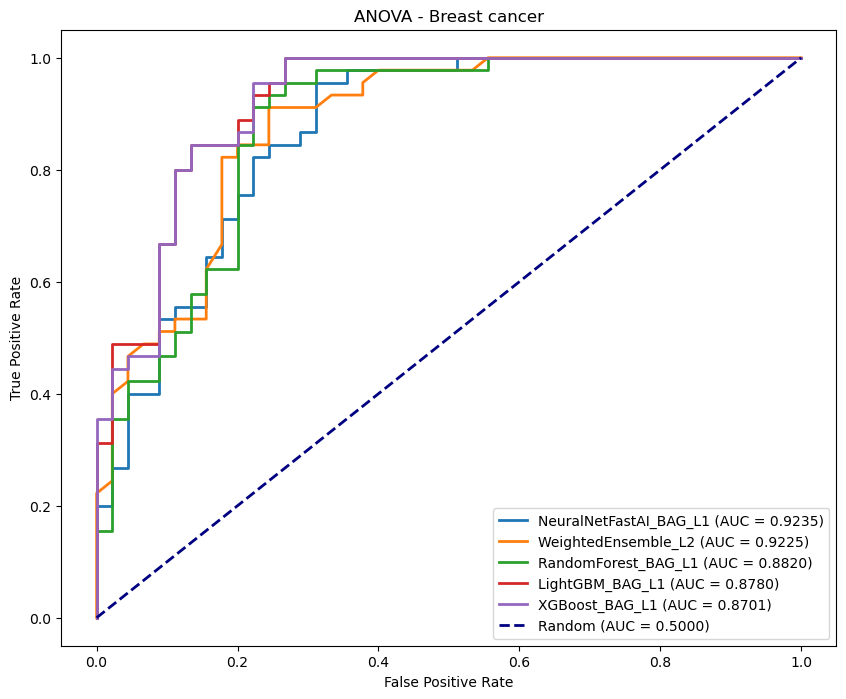

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ANOVA(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)  # 只取正类概率
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ANOVA - Breast cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Breast cancer/ANOVA'
data = ANOVAdata 
plot_roc_curves_ANOVA(data, model_dir)


##### ReliefF

In [4]:
# 加载数据集
file_path = '../ReliefF/breast_sample_ReliefFSorted_selected119.csv'
ReliefFdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [5]:
ReliefFdata

,class,MOTIF_END_ATAT,MOTIF_END_TGCA,MOTIF_END_AAAT,MOTIF_END_AAAC,MOTIF_END_ATTT,MOTIF_END_TGAC,MOTIF_END_ACAC,MOTIF_END_ACAT,MOTIF_END_CAAC,...,MOTIF_END_TATA,MOTIF_END_ATGC,MOTIF_END_GGAT,MOTIF_END_CGCC,MOTIF_END_CGCG,MOTIF_END_GAAT,MOTIF_END_GGAG,MOTIF_END_GAAC,MOTIF_END_GGCA,CNA_10:133000001-134000000
0,1,0.005263,0.004784,0.009446,0.005210,0.007665,0.003342,0.004264,0.006115,0.003608,...,0.006632,0.002865,0.003615,0.000651,0.000318,0.005013,0.007092,0.003038,0.005716,1.14534
1,1,0.005114,0.004583,0.008931,0.005066,0.007451,0.003321,0.004421,0.006049,0.003710,...,0.006156,0.002897,0.003409,0.000651,0.000340,0.004631,0.006983,0.002855,0.005398,1.09536
2,1,0.005290,0.004733,0.009448,0.005208,0.007627,0.003449,0.004378,0.006350,0.003603,...,0.006696,0.002814,0.003629,0.000556,0.000260,0.005074,0.007001,0.003058,0.005631,1.13443
3,1,0.005001,0.004872,0.009043,0.005106,0.007338,0.003419,0.004326,0.006024,0.003562,...,0.006248,0.002838,0.003622,0.000663,0.000327,0.004845,0.007496,0.003069,0.005863,1.16705
4,1,0.005384,0.004480,0.009591,0.005333,0.007579,0.003307,0.004310,0.006151,0.003683,...,0.006416,0.002972,0.003514,0.000521,0.000253,0.005070,0.007182,0.003071,0.005603,1.12200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,0,0.005366,0.005118,0.009235,0.005238,0.007558,0.003386,0.004246,0.005894,0.003496,...,0.006224,0.002988,0.003323,0.000757,0.000397,0.004681,0.006877,0.002847,0.005360,1.13364
442,0,0.004996,0.005404,0.008982,0.005048,0.007651,0.003636,0.004168,0.005558,0.003351,...,0.005665,0.002894,0.003356,0.000941,0.000496,0.004430,0.006896,0.002802,0.005395,1.17866
443,0,0.004540,0.005511,0.008334,0.004732,0.006853,0.003687,0.003973,0.005249,0.003230,...,0.005329,0.002858,0.003781,0.000855,0.000464,0.005059,0.007721,0.003142,0.006186,1.17347
444,0,0.005202,0.005020,0.009202,0.005154,0.007855,0.003478,0.004260,0.005890,0.003439,...,0.006019,0.002874,0.003594,0.000827,0.000432,0.004511,0.007253,0.002812,0.005686,1.16027


In [ ]:
# 准备训练和测试集函数
def prepare_train_test_ReliefF(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    # train_data, test_data = train_test_split(data, test_size=0.2, random_state=42, stratify=data['class'])
    # val_data, test_data = train_test_split(test_data, test_size=0.5, random_state=42, stratify=test_data['class'])

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ReliefF/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    predictor=TabularPredictor.load(f"/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Breast cancer/ReliefF")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [20]:
Breast_leaderboard_ReliefF = prepare_train_test_ReliefF(ReliefFdata, "Breast cancer", output_dir)
Breast_leaderboard_ReliefF

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI_BAG_L1,0.962451,0.911111,0.910079,0.825064,0.904762,0.950000,0.863636,0.962451,0.931069,roc_auc,0.761733,0.155706,8.770998,0.761733,0.155706,8.770998,1,True,3
1,WeightedEnsemble_L2,0.958498,0.933333,0.932806,0.867328,0.930233,0.952381,0.909091,0.958498,0.936908,roc_auc,0.905720,0.174500,9.661314,0.001703,0.000492,0.022687,2,True,5
2,LightGBM_BAG_L1,0.926877,0.822222,0.823123,0.647526,0.826087,0.791667,0.863636,0.926877,0.904810,roc_auc,0.142285,0.018303,0.867629,0.142285,0.018303,0.867629,1,True,1
3,RandomForest_BAG_L1,0.924901,0.844444,0.844862,0.689723,0.844444,0.826087,0.863636,0.924901,0.898703,roc_auc,0.048408,0.138013,1.147287,0.048408,0.138013,1.147287,1,True,2
4,XGBoost_BAG_L1,0.922925,0.844444,0.844862,0.689723,0.844444,0.826087,0.863636,0.922925,0.884358,roc_auc,0.280924,0.056448,1.850462,0.280924,0.056448,1.850462,1,True,4


In [ ]:
Breast_leaderboard_ReliefF = prepare_train_test_ReliefF(ReliefFdata, "Breast cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       158.31 GB / 251.54 GB (62.9%)
Disk Space Avail:   8941.61 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [37]:
Breast_leaderboard_ReliefF.to_csv("breast_leaderboard_ReliefF.csv", index=False)
Breast_leaderboard_ReliefF

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI_BAG_L1,0.961481,0.900000,0.900000,0.801784,0.896552,0.928571,0.866667,0.961481,0.931069,roc_auc,0.796641,0.155706,8.770998,0.796641,0.155706,8.770998,1,True,3
1,WeightedEnsemble_L2,0.959012,0.900000,0.900000,0.800198,0.901099,0.891304,0.911111,0.959012,0.936908,roc_auc,0.959961,0.174500,9.661314,0.001993,0.000492,0.022687,2,True,5
2,RandomForest_BAG_L1,0.935062,0.844444,0.844444,0.691627,0.851064,0.816327,0.888889,0.935062,0.898703,roc_auc,0.070468,0.138013,1.147287,0.070468,0.138013,1.147287,1,True,2
3,XGBoost_BAG_L1,0.933333,0.855556,0.855556,0.715542,0.863158,0.820000,0.911111,0.933333,0.884358,roc_auc,0.292027,0.056448,1.850462,0.292027,0.056448,1.850462,1,True,4
4,LightGBM_BAG_L1,0.930370,0.844444,0.844444,0.695095,0.854167,0.803922,0.911111,0.930370,0.904810,roc_auc,0.161327,0.018303,0.867629,0.161327,0.018303,0.867629,1,True,1


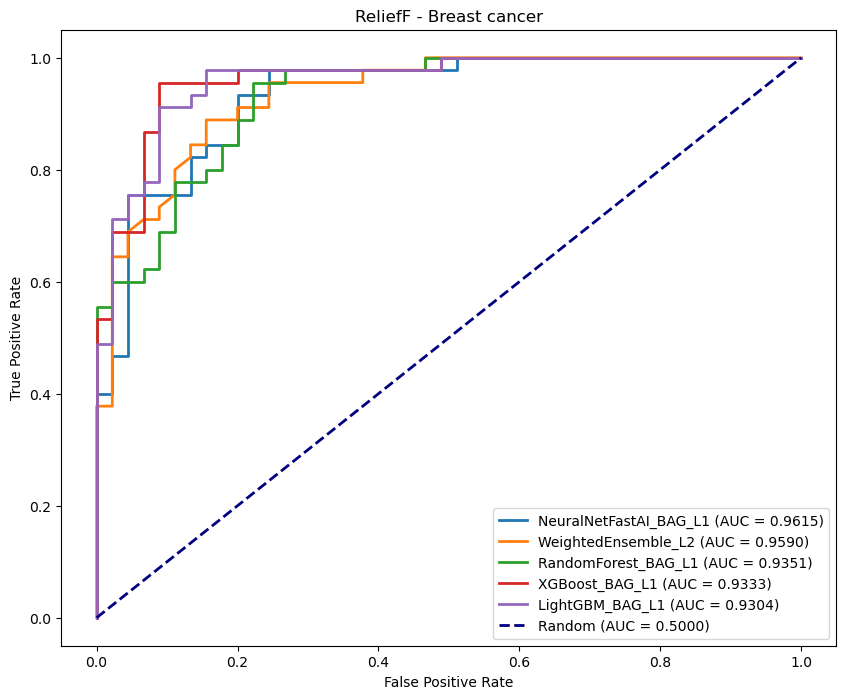

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ReliefF(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ReliefF - Breast cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Breast cancer/ReliefF'
data = ReliefFdata 
plot_roc_curves_ReliefF(data, model_dir)


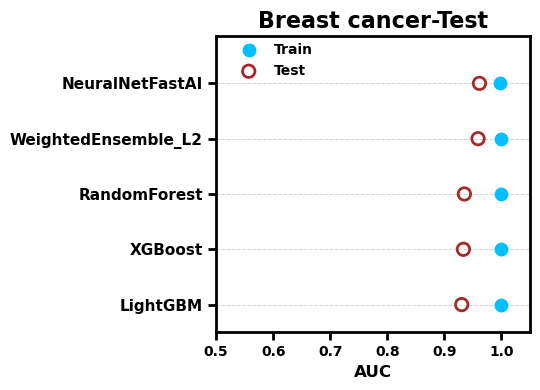

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
import pandas as pd

def plot_model_auc_dotplot(data, model_dir):
    predictor = TabularPredictor.load(model_dir)
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

    # 分层采样
    train_data, test_data = train_test_split(data, test_size=0.2, random_state=42, stratify=data['class'])

    auc_train = []
    auc_val = []

    for model_name in models:
        model = predictor._trainer.load_model(model_name)

        y_train = train_data['class']
        y_val = test_data['class']

        y_prob_train = model.predict_proba(train_data)
        y_prob_val = model.predict_proba(test_data)

        if isinstance(y_prob_train, pd.DataFrame):
            y_prob_train = y_prob_train.iloc[:, 1]
            y_prob_val = y_prob_val.iloc[:, 1]

        auc_tr = roc_auc_score(y_train, y_prob_train)
        auc_te = roc_auc_score(y_val, y_prob_val)

        auc_train.append(auc_tr)
        auc_val.append(auc_te)


    # 按验证集 AUC 降序排列
    combined = list(zip(models, auc_train, auc_val))
    combined.sort(key=lambda x: x[2], reverse=False)  # x[2] 是 validation AUC

    model_labels = [x[0].replace('_BAG_L1', '') for x in combined]
    auc_train_sorted = [x[1] for x in combined]
    auc_val_sorted = [x[2] for x in combined]
    y_pos = list(range(len(models)))

    # 图像设置
    fig, ax = plt.subplots(figsize=(5.5, 4))
    ax.scatter(auc_train_sorted, y_pos, color='deepskyblue', label='Train', s=80, zorder=3)
    ax.scatter(auc_val_sorted, y_pos, facecolors='none', edgecolors='brown', label='Test', s=80, linewidths=2, zorder=3)
  
    # 分隔线
    for y in y_pos:
        ax.hlines(y, 0.5, 1.05, color='lightgray', linestyle='--', linewidth=0.7, zorder=0)

    ax.set_yticks(y_pos)

    ax.set_xlabel("AUC", fontsize=12, fontweight='bold')
    ax.set_title("Breast cancer-Test", fontsize=16, fontweight='bold')

    # 上边多留一点空，左边多留一点空间
    ax.set_xlim(0.5, 1.05)
    ax.set_ylim(-0.5, len(models) - 0.85 + 0.7)
    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)
        
    ax = plt.gca()  # 获取当前坐标轴
    for spine in ax.spines.values():
        spine.set_linewidth(2)
    ax.tick_params(axis='both', width=2, length=6)
    for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
        tick_label.set_fontsize(10)
        tick_label.set_fontweight('bold')
    ax.set_yticklabels(model_labels, fontsize=11)

    # 图例放左上角
    ax.legend(loc='upper left', bbox_to_anchor=(0.02, 1.02), frameon=False, prop={'family': 'sans-serif', 'size': 10, 'weight': 'bold'})
    # plt.subplots_adjust(left=0.33, right=0.95, top=0.92, bottom=0.11)
    plt.tight_layout()
    plt.savefig(f"{model_dir}_AUC_dotplot.png", dpi=300)
    plt.show()

# 调用
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Breast cancer/ReliefF'
data = ReliefFdata
plot_model_auc_dotplot(data, model_dir)


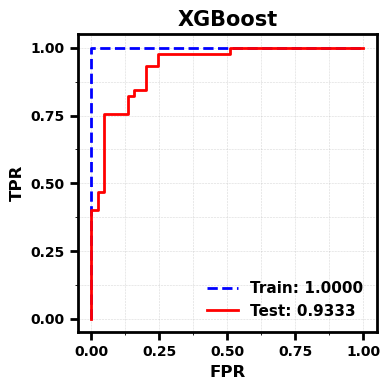

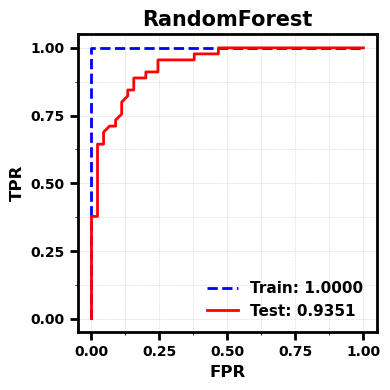

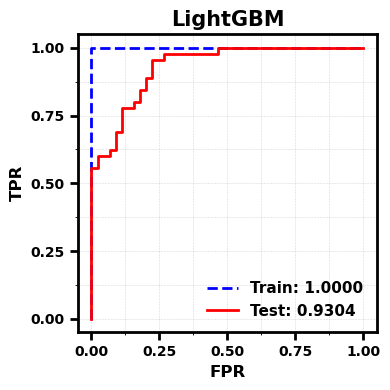

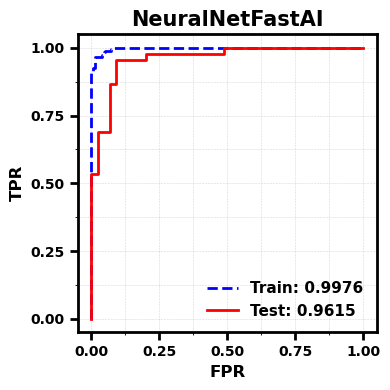

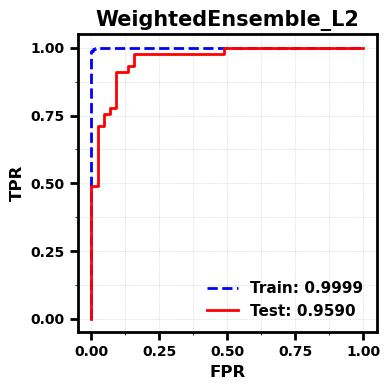

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
import pandas as pd
import os
import numpy as np

def plot_model_roc_curves(data, model_dir, output_dir='ROC_plots'):
    predictor = TabularPredictor.load(model_dir)
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

    # 数据划分
    train_data, test_data = train_test_split(data, test_size=0.2, random_state=42, stratify=data['class'])

    output_path = os.path.join(model_dir, output_dir)
    os.makedirs(output_path, exist_ok=True)

    for model_name in models:
        model = predictor._trainer.load_model(model_name)

        fig, ax = plt.subplots(figsize=(4, 4))

        for dataset_name, dataset, color in zip(
            ['Train', 'Test'],
            [train_data, test_data],
            ['blue', 'red']
        ):
            y_true = dataset['class']
            y_proba = model.predict_proba(dataset)
            if isinstance(y_proba, pd.DataFrame):
                y_proba = y_proba.iloc[:, 1]
            fpr, tpr, _ = roc_curve(y_true, y_proba)
            roc_auc = auc(fpr, tpr)
            linestyle = '--' if dataset_name == 'Train' else '-'
            ax.plot(fpr, tpr, label=f"{dataset_name}: {roc_auc:.4f}", color=color, linestyle=linestyle, linewidth=2)

        # 设置坐标刻度和标签
        ticks = np.linspace(0, 1, 5)
        tick_labels = [f'{t:.2f}' for t in ticks]
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        ax.set_xticklabels(tick_labels)
        ax.set_yticklabels(tick_labels)
        
        # 更密集的网格线
        ax.set_xlim([-0.05, 1.05])
        ax.set_ylim([-0.05, 1.05])
        ax.set_xticks(np.linspace(0, 1, 9), minor=True)
        ax.set_yticks(np.linspace(0, 1, 9), minor=True)
        ax.tick_params(axis='both', which='major', direction='out', length=6, width=1.2, labelsize=10)
        ax.grid(True, which='both', linestyle='--', linewidth=0.4, alpha=0.5)

        for spine in ax.spines.values():
            spine.set_edgecolor('black')
            spine.set_linewidth(2)
        
        clean_name = model_name.replace('_BAG_L1', '')
        ax.set_title(clean_name, fontsize=15, fontweight='bold')

        ax.set_xlabel("FPR", fontsize=12, fontweight='bold')
        ax.set_ylabel("TPR", fontsize=12, fontweight='bold')

        ax = plt.gca()  # 获取当前坐标轴
        for spine in ax.spines.values():
            spine.set_linewidth(2)
        ax.tick_params(axis='both', width=2, length=6)
        for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
            # tick_label.set_fontsize(10)
            tick_label.set_fontweight('bold')

        # 去掉图例边框
        ax.legend(loc="lower right", fontsize=8, frameon=False, prop={'size': 11, 'weight': 'bold'})

        plt.tight_layout()
        plt.savefig(os.path.join(output_path, f"{model_name}_ROC.png"), dpi=300)
        plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Breast cancer/ReliefF'
data = ReliefFdata
plot_model_roc_curves(data, model_dir)


In [6]:
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, recall_score, precision_score
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 重新加载模型和数据
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Breast cancer/ReliefF'
predictor = TabularPredictor.load(model_dir)
data = ReliefFdata

# 模型名称列表
models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

# 数据划分
train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)

# 用于保存结果
results = []

# 遍历每个模型并计算各项指标
for model_name in models:
    model = predictor._trainer.load_model(model_name)
    
    for set_name, df in [('Train', train_data), ('Test', test_data)]:
        y_true = df['class']
        y_proba = model.predict_proba(df)
        if isinstance(y_proba, pd.DataFrame):
            y_score = y_proba.iloc[:, 1]
        else:
            y_score = y_proba
        y_pred = (y_score >= 0.5).astype(int)

        results.append({
            'Model': model_name,
            'Set': set_name,
            'AUC': roc_auc_score(y_true, y_score),
            'Accuracy': accuracy_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred)
        })

# 转换为 DataFrame 展示
results_df = pd.DataFrame(results)
# 按 Test AUC 排序，仅保留 Test 行并根据 AUC 降序排列后提取顺序索引
test_auc_order = results_df[results_df['Set'] == 'Test'].sort_values(by='AUC', ascending=False)['Model']

# 按上述顺序重新排列整个结果 DataFrame（Validation 和 Test 行都保持）
results_df['Model'] = pd.Categorical(results_df['Model'], categories=test_auc_order, ordered=True)
results_df = results_df.sort_values(by=['Model', 'Set']).reset_index(drop=True)
results_df

,Model,Set,AUC,Accuracy,F1,Recall,Precision
0,NeuralNetFastAI_BAG_L1,Test,0.961481,0.900000,0.896552,0.866667,0.928571
1,NeuralNetFastAI_BAG_L1,Train,0.997570,0.971910,0.971751,0.966292,0.977273
2,WeightedEnsemble_L2,Test,0.959012,0.900000,0.901099,0.911111,0.891304
3,WeightedEnsemble_L2,Train,0.999905,0.994382,0.994350,0.988764,1.000000
4,RandomForest_BAG_L1,Test,0.935062,0.844444,0.851064,0.888889,0.816327
5,RandomForest_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
6,XGBoost_BAG_L1,Test,0.933333,0.855556,0.863158,0.911111,0.820000
7,XGBoost_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
8,LightGBM_BAG_L1,Test,0.930370,0.844444,0.854167,0.911111,0.803922
9,LightGBM_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000


##### Binomial

In [53]:
# 加载数据集
file_path = '../Binomial/breast_sample_BinomialSorted_selected230.csv'
Binomialdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [54]:
Binomialdata

,class,CNA_1:13000001-14000000,CNA_4:9000001-10000000,TMD_98,TMD_350,CNA_22:21000001-22000000,CNA_16:90000001-90354753,TMD_131,TMD_268,TMD_392,...,TMD_331,TMD_334,TMD_356,TMD_373,TMD_386,TMD_420,TMD_431,MOTIF_END_CAAC,MOTIF_END_CGTT,MOTIF_END_GCCA
0,1,0.967960,1.023870,0.000000,0.000000,1.11073,1.27575,0.045977,0.000000,0.000000,...,0.004695,0.073826,0.066556,0.156250,0.093607,0.862069,0.000000,0.003608,0.000817,0.005210
1,1,0.970525,0.944520,0.000000,0.046512,1.09161,1.32385,0.010183,0.012090,0.002350,...,0.021784,0.035349,0.021726,0.048780,0.097765,0.917031,0.038997,0.003710,0.000763,0.005049
2,1,0.965195,1.018910,0.000000,0.000000,1.05969,1.10352,0.054054,0.045455,0.000000,...,0.000000,0.130719,0.043919,0.020305,0.068127,0.965812,0.111111,0.003603,0.000816,0.005126
3,1,0.925010,0.949515,0.000000,0.000000,1.04471,1.20603,0.013423,0.017544,0.000000,...,0.014620,0.023599,0.041475,0.070370,0.007712,0.992188,0.013699,0.003562,0.000841,0.005360
4,1,1.255090,1.226660,0.300813,0.000000,1.02235,1.30905,0.000000,0.005464,0.513513,...,0.482297,0.211663,0.281818,0.281579,0.444985,0.764706,0.319149,0.003683,0.000755,0.004819
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,0,0.923612,0.921408,0.037037,0.000000,1.03597,1.42804,0.003597,0.000000,0.000000,...,0.045151,0.027586,0.060274,0.017094,0.016691,0.987013,0.118644,0.003496,0.000895,0.005022
442,0,0.958038,0.920887,0.012048,0.000000,1.09585,1.53302,0.011038,0.000000,0.005000,...,0.060801,0.014249,0.037291,0.052209,0.055739,0.877551,0.040268,0.003351,0.000970,0.005469
443,0,0.983011,0.906756,0.000000,0.000000,1.04088,1.41372,0.020000,0.000000,0.000000,...,0.059459,0.051724,0.015228,0.034884,0.110092,0.909091,0.181818,0.003230,0.001014,0.005992
444,0,0.928419,0.900363,0.000000,0.000000,1.07485,1.32900,0.034091,0.032051,0.000000,...,0.017065,0.007407,0.010590,0.035088,0.069892,0.941176,0.164557,0.003439,0.000891,0.005292


In [40]:
# 准备训练和测试集函数
def prepare_train_test_Binomial(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Binomial/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [41]:
Breast_leaderboard_Binomial = prepare_train_test_Binomial(Binomialdata, "Breast cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       158.07 GB / 251.54 GB (62.8%)
Disk Space Avail:   8943.79 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [42]:
Breast_leaderboard_Binomial.to_csv("breast_leaderboard_Binomial.csv", index=False)
Breast_leaderboard_Binomial

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,RandomForest_BAG_L1,0.848395,0.722222,0.722222,0.444554,0.725275,0.717391,0.733333,0.848395,0.796475,roc_auc,0.059072,0.117626,1.134885,0.059072,0.117626,1.134885,1,True,2
1,WeightedEnsemble_L2,0.846420,0.744444,0.744444,0.489010,0.747253,0.739130,0.755556,0.846420,0.818299,roc_auc,1.087780,0.436126,14.828961,0.002433,0.000474,0.045264,2,True,5
2,LightGBM_BAG_L1,0.840494,0.800000,0.800000,0.602385,0.808511,0.775510,0.844444,0.840494,0.778658,roc_auc,0.146089,0.017373,1.106338,0.146089,0.017373,1.106338,1,True,1
3,XGBoost_BAG_L1,0.840494,0.777778,0.777778,0.557763,0.787234,0.755102,0.822222,0.840494,0.773987,roc_auc,0.308936,0.079001,4.472634,0.308936,0.079001,4.472634,1,True,4
4,NeuralNetFastAI_BAG_L1,0.788642,0.711111,0.711111,0.422222,0.711111,0.711111,0.711111,0.788642,0.770073,roc_auc,0.717338,0.239025,9.176178,0.717338,0.239025,9.176178,1,True,3


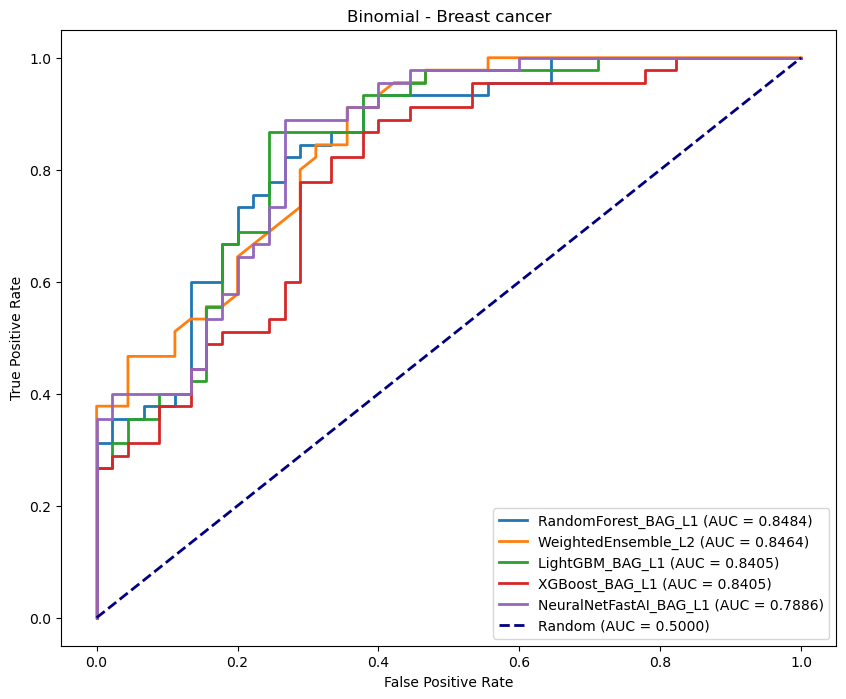

In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_Binomial(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Binomial - Breast cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_Breast cancer/Binomial'
data = Binomialdata 
plot_roc_curves_Binomial(data, model_dir)


### biomaker分析

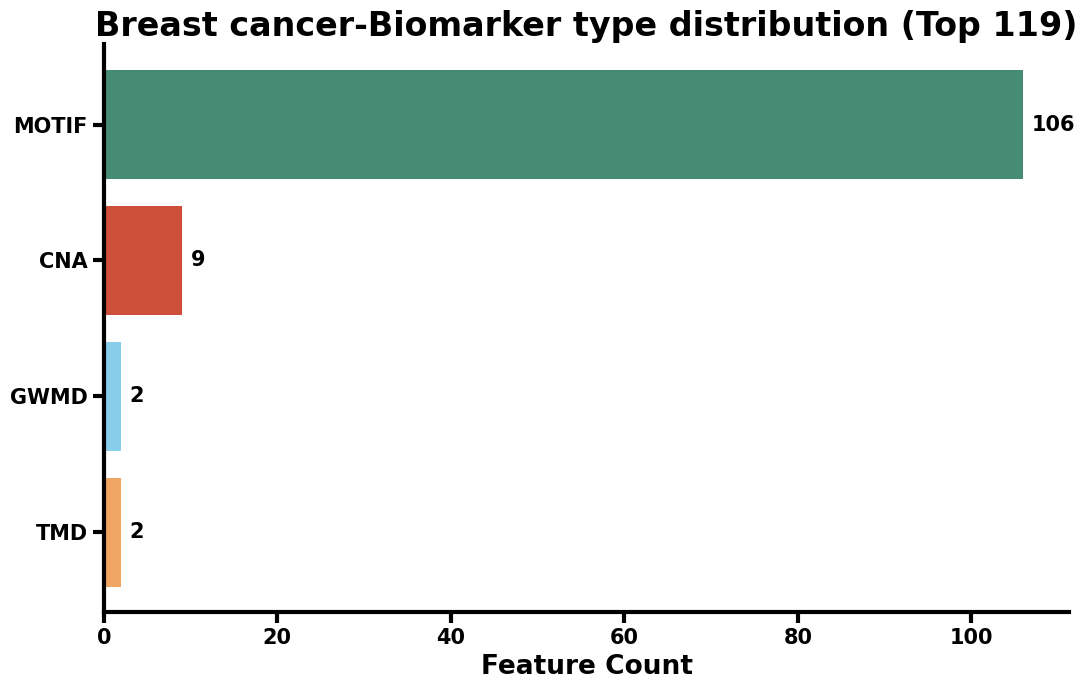

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 读取数据
file_path = '/home/xwluo/cfDNA/elife/ReliefF/breast_feature_importance.csv'
df = pd.read_csv(file_path, header=None, names=['Index', 'Marker', 'Value'])
df = df.head(119)

# 分类函数
def classify_marker(marker):
    if "GWMD" in marker:
        return "GWMD"
    elif "TMD" in marker:
        return "TMD"
    elif "GWFP" in marker:
        return "GWFP"
    elif "flen" in marker:
        return "flen"
    elif "MOTIF" in marker:
        return "MOTIF"
    elif "CNA" in marker:
        return "CNA"
    else:
        return "Other"

df['Type'] = df['Marker'].apply(classify_marker)
type_counts = df['Type'].value_counts().sort_values(ascending=True)

# 手动设置每类颜色（可根据需要修改）
custom_colors = {
    'TMD': '#f1a562',
    'GWMD': '#88cdea',
    'GWFP': '#7570b3',
    'flen': '#e7298a',
    'MOTIF': '#468c74',
    'CNA': '#cd4f39',
    'Other': '#a6761d'
}

# 绘制条形图
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(type_counts.index, type_counts.values, color=[custom_colors.get(t, 'black') for t in type_counts.index])

# 添加文本标签
for bar in bars:
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f'{int(bar.get_width())}', va='center', fontsize=15, fontweight='bold')

# 轴设置
ax.set_xlabel("Feature Count", fontsize=19, fontweight='bold')
# ax.set_ylabel("Biomarker Type", fontsize=12)
ax.set_title("Breast cancer-Biomarker type distribution (Top 119)", fontsize=24, fontweight='bold')

# 去掉网格线，保留边框
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# plt.yticks(fontweight='bold')
ax = plt.gca()  # 获取当前坐标轴
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

plt.tight_layout()
plt.savefig("Breast-ReliefF-Barplot-BiomarkerTypes_NoGrid.png", dpi=300)
plt.show()


## 多癌种biomaker相似性分析

<Figure size 1000x800 with 0 Axes>

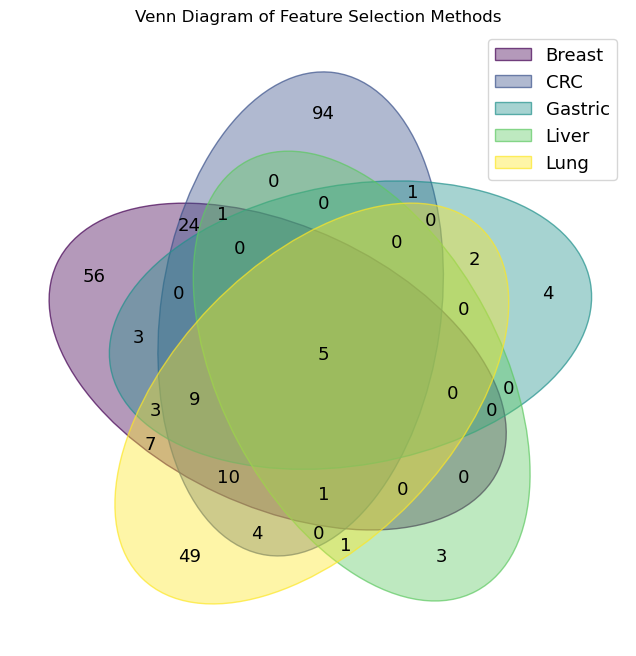

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
from venn import venn

# 文件路径列表
file_path_Breast = '/home/xwluo/cfDNA/elife/ReliefF/breast_feature_importance.csv'
file_path_CRC = '/home/xwluo/cfDNA/elife/Fscore/CRC_feature_importance.csv'
file_path_Gastric = '/home/xwluo/cfDNA/elife/ReliefF/Gastric_feature_importance.csv'
file_path_Liver = '/home/xwluo/cfDNA/elife/ReliefF/Liver_feature_importance.csv'
file_path_Lung = '/home/xwluo/cfDNA/elife/ReliefF/Lung_feature_importance.csv'

# 存储每个文件中的标记集合
marker_sets = {}

df_Breast = pd.read_csv(file_path_Breast, header=None, names=['Index', 'Marker', 'Value'])
df_Breast = df_Breast.head(119)
markers_Breast = set(df_Breast['Marker'])
marker_sets['Breast'] = markers_Breast

df_CRC = pd.read_csv(file_path_CRC, sep='\t', header=None, names=['Index', 'Marker', 'Value'])
df_CRC = df_CRC.head(149)
markers_CRC = set(df_CRC['Marker'])
marker_sets['CRC'] = markers_CRC

df_Gastric = pd.read_csv(file_path_Gastric, header=None, names=['Index', 'Marker', 'Value'])
df_Gastric = df_Gastric.head(27)
markers_Gastric = set(df_Gastric['Marker'])
marker_sets['Gastric'] = markers_Gastric

df_Liver = pd.read_csv(file_path_Liver, header=None, names=['Index', 'Marker', 'Value'])
df_Liver = df_Liver.head(11)
markers_Liver = set(df_Liver['Marker'])
marker_sets['Liver'] = markers_Liver

df_Lung = pd.read_csv(file_path_Lung, header=None, names=['Index', 'Marker', 'Value'])
df_Lung = df_Lung.head(91)
markers_Lung = set(df_Lung['Marker'])
marker_sets['Lung'] = markers_Lung

# 绘制 Venn 图
plt.figure(figsize=(10, 8))
venn(marker_sets)
plt.title('Venn Diagram of Feature Selection Methods')
plt.show()